# Notebook 4: Discovering an Unknown Rate Law with jaxsr

Notebooks 2 and 3 assume the rate law is known and estimate its constants. Often
the *form* of the rate law is the unknown: is a step first or second order, does
it saturate, is it inhibited by a product? This notebook pairs kipetax with
[jaxsr](https://github.com/jkitchin/jaxsr), a symbolic-regression package that
selects a sparse expression from a library of candidate terms, and works through
a two-stage ("discover, then refit") workflow:

1. **Estimate rates** from the measured concentration trajectories by numerical
   differentiation.
2. **Discover** each rate law with jaxsr: choose a few terms from a library of
   chemically sensible candidates, scored by BIC.
3. **Translate** the discovered expressions into kipetax expressions, turning
   every fitted constant into a parameter.
4. **Refit** the discovered model with kipetax against the *raw trajectories* of
   all experiments at once.

Step 2 fits numerically differentiated data, which is noisier than the
measurements and biased by the smoothing that makes differentiation possible.
Step 4 fits the measurements themselves, through the ODE integrator, with the
correct noise weighting. That makes it both the final estimate and a check of
the discovered model against the raw data.

**What is assumed known:** the stoichiometry. The network is A → B and 2B → C,
so

$$\frac{dA}{dt} = -r_1, \qquad \frac{dB}{dt} = r_1 - 2r_2, \qquad \frac{dC}{dt} = r_2 .$$

**What is unknown:** the rate laws $r_1$ and $r_2$.

Requires `pip install jaxsr` (tested with jaxsr 0.3.0).

In [1]:
import sys
sys.path.insert(0, '..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import jax.numpy as jnp
import sympy as sp
from scipy.integrate import solve_ivp

import kipetax
from kipetax import ReactionModel, ReactionSet
from jaxsr import BasisLibrary, SymbolicRegressor, estimate_derivatives

## Synthetic experiments

The data come from a "true" mechanism that the rest of the notebook does not get
to see, except to grade the answer at the end:

- $r_1 = \dfrac{k_1 A}{1 + K A}$, a saturating (Langmuir-Hinshelwood /
  Michaelis-Menten) step, with $k_1 = 2$, $K = 1.5$;
- $r_2 = k_2 B^2$, a second-order step, with $k_2 = 0.8$.

The saturating form is the interesting one. Over a narrow range of $A$ it is
nearly indistinguishable from a polynomial such as $aA - bA^2$, so the
experiments must span a wide range of $A$. We run four batch experiments with
different initial charges, sample 121 times over $[0, 6]$, and add Gaussian noise
with $\sigma = 0.01$. The trajectories are integrated with SciPy, independently
of kipetax.

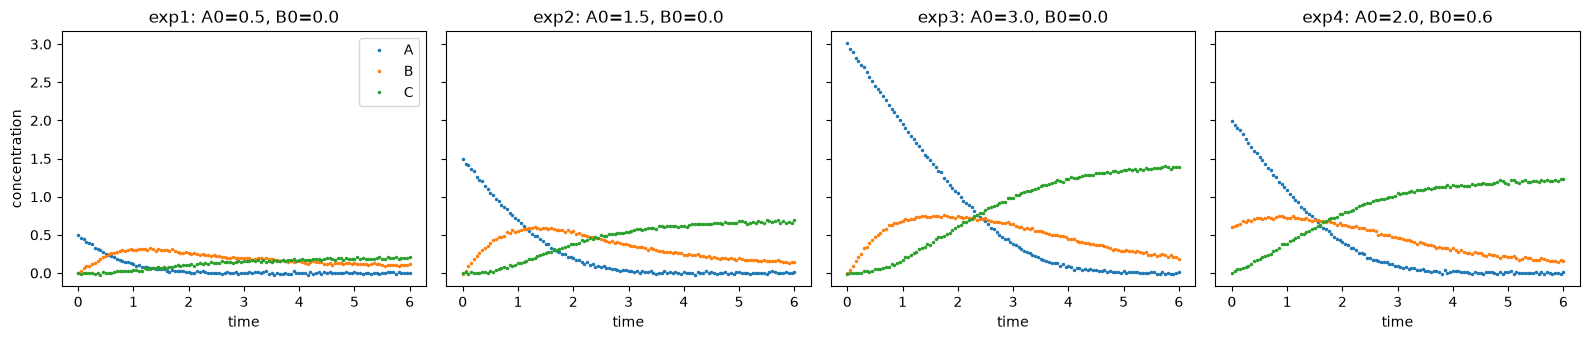

In [2]:
TRUE = {'k1': 2.0, 'K': 1.5, 'k2': 0.8}   # used only to grade the result


def true_rhs(t, y):
    A, B, C = y
    r1 = TRUE['k1'] * A / (1 + TRUE['K'] * A)
    r2 = TRUE['k2'] * B**2
    return [-r1, r1 - 2 * r2, r2]


EXPERIMENTS = {            # initial charge (A0, B0, C0)
    'exp1': (0.5, 0.0, 0.0),
    'exp2': (1.5, 0.0, 0.0),
    'exp3': (3.0, 0.0, 0.0),
    'exp4': (2.0, 0.6, 0.0),
}
SIGMA = 0.01
t = np.linspace(0.0, 6.0, 121)


def make_data(sigma, seed=7):
    rng = np.random.default_rng(seed)
    data = {}
    for name, y0 in EXPERIMENTS.items():
        sol = solve_ivp(true_rhs, (t[0], t[-1]), y0, t_eval=t, rtol=1e-10, atol=1e-12)
        data[name] = pd.DataFrame(sol.y.T + rng.normal(0.0, sigma, (len(t), 3)),
                                  index=t, columns=['A', 'B', 'C'])
    return data


data = make_data(SIGMA)

fig, axes = plt.subplots(1, 4, figsize=(16, 3.5), sharey=True)
for ax, (name, df) in zip(axes, data.items()):
    for comp, color in zip('ABC', ['tab:blue', 'tab:orange', 'tab:green']):
        ax.plot(df.index, df[comp], '.', ms=3, color=color, label=comp)
    ax.set_title(f'{name}: A0={EXPERIMENTS[name][0]}, B0={EXPERIMENTS[name][1]}')
    ax.set_xlabel('time')
axes[0].set_ylabel('concentration')
axes[0].legend()
plt.tight_layout()
plt.show()

## Step 1: Estimate the rates

Each rate is read off one species through the stoichiometry: $r_1 = -dA/dt$ and
$r_2 = dC/dt$. Derivatives come from a Savitzky-Golay filter (a local cubic fit
over 21 points), which smooths the noise that plain finite differences would
amplify.

The third balance gives a free consistency check: $dB/dt$ should equal
$r_1 - 2r_2$. If it did not, the assumed stoichiometry would be wrong, and no
rate law could fix that.

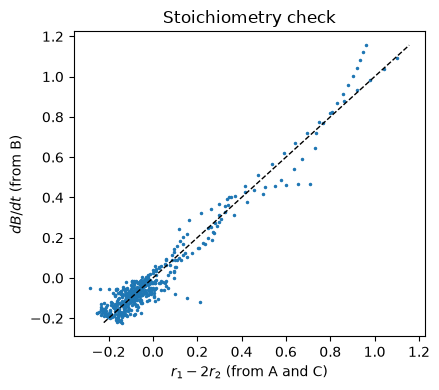

484 rate estimates; stoichiometry residual RMS = 0.0578


In [3]:
def estimate_rates(data, window=21):
    X, R1, R2, dB = [], [], [], []
    for df in data.values():
        Y = df[['A', 'B', 'C']].values
        dY = estimate_derivatives(Y, df.index.values, method='savgol',
                                  window_length=window, polyorder=3)
        X.append(Y)
        R1.append(-dY[:, 0])
        R2.append(dY[:, 2])
        dB.append(dY[:, 1])
    return np.vstack(X), np.concatenate(R1), np.concatenate(R2), np.concatenate(dB)


X, r1_est, r2_est, dB_est = estimate_rates(data)

fig, ax = plt.subplots(figsize=(4.5, 4))
ax.plot(r1_est - 2 * r2_est, dB_est, '.', ms=3)
lim = [dB_est.min(), dB_est.max()]
ax.plot(lim, lim, 'k--', lw=1)
ax.set_xlabel(r'$r_1 - 2 r_2$ (from A and C)')
ax.set_ylabel(r'$dB/dt$ (from B)')
ax.set_title('Stoichiometry check')
plt.tight_layout()
plt.show()
print(f"{len(r1_est)} rate estimates; stoichiometry residual RMS = "
      f"{np.sqrt(np.mean((dB_est - (r1_est - 2 * r2_est))**2)):.3g}")

## Step 2: Candidate rate laws

The library is where the chemistry goes in. A generic library (all polynomials
and products of A, B, C) gives the regression room to fit noise in the
derivatives with terms that make no chemical sense. Two rules keep it honest:

- **A rate must vanish when its reactant is absent.** Every candidate for $r_1$
  contains $A$; every candidate for $r_2$ contains $B$.
- **Include the plausible competing mechanisms**: first or second order,
  saturation, and inhibition by each other species.

Saturation and inhibition terms carry an inner constant $K$ that enters
nonlinearly. jaxsr handles these with `add_parametric`: for each trial $K$ the
outer coefficients are solved exactly by least squares, and $K$ is optimized by
profile likelihood.

In [4]:
K_RANGE = {'K': (0.05, 20.0)}
NAMES = ['A', 'B', 'C']


def library_r1():
    lib = BasisLibrary(n_features=3, feature_names=NAMES)
    lib.add_custom('A',   lambda X: X[:, 0],           complexity=1, feature_indices=(0,))
    lib.add_custom('A^2', lambda X: X[:, 0]**2,        complexity=2, feature_indices=(0,))
    lib.add_custom('A*B', lambda X: X[:, 0] * X[:, 1], complexity=2, feature_indices=(0, 1))
    lib.add_custom('A*C', lambda X: X[:, 0] * X[:, 2], complexity=2, feature_indices=(0, 2))
    lib.add_parametric('A/(1+K*A)', lambda X, K: X[:, 0] / (1 + K * X[:, 0]),
                       K_RANGE, feature_indices=(0,), log_scale=True)    # saturation
    lib.add_parametric('A/(1+K*B)', lambda X, K: X[:, 0] / (1 + K * X[:, 1]),
                       K_RANGE, feature_indices=(0, 1), log_scale=True)  # inhibition by B
    lib.add_parametric('A/(1+K*C)', lambda X, K: X[:, 0] / (1 + K * X[:, 2]),
                       K_RANGE, feature_indices=(0, 2), log_scale=True)  # inhibition by C
    return lib


def library_r2():
    lib = BasisLibrary(n_features=3, feature_names=NAMES)
    lib.add_custom('B',   lambda X: X[:, 1],           complexity=1, feature_indices=(1,))
    lib.add_custom('B^2', lambda X: X[:, 1]**2,        complexity=2, feature_indices=(1,))
    lib.add_custom('A*B', lambda X: X[:, 0] * X[:, 1], complexity=2, feature_indices=(0, 1))
    lib.add_custom('B*C', lambda X: X[:, 1] * X[:, 2], complexity=2, feature_indices=(1, 2))
    lib.add_parametric('B/(1+K*B)', lambda X, K: X[:, 1] / (1 + K * X[:, 1]),
                       K_RANGE, feature_indices=(1,), log_scale=True)
    lib.add_parametric('B^2/(1+K*B)', lambda X, K: X[:, 1]**2 / (1 + K * X[:, 1]),
                       K_RANGE, feature_indices=(1,), log_scale=True)
    return lib


print('r1 candidates: A, A^2, A*B, A*C, A/(1+K*A), A/(1+K*B), A/(1+K*C)')
print('r2 candidates: B, B^2, A*B, B*C, B/(1+K*B), B^2/(1+K*B)')
print(f'library sizes: {len(library_r1().basis_functions)} and {len(library_r2().basis_functions)} terms')

r1 candidates: A, A^2, A*B, A*C, A/(1+K*A), A/(1+K*B), A/(1+K*C)
r2 candidates: B, B^2, A*B, B*C, B/(1+K*B), B^2/(1+K*B)
library sizes: 7 and 6 terms


## Step 3: Discover the rate laws

`SymbolicRegressor` grows each model greedily, one term at a time, up to
`max_terms`, and keeps the model with the lowest BIC. BIC charges for every extra
term, so a term is kept only when it explains substantially more of the data.

In [5]:
def discover(library, X, y, max_terms=3):
    model = SymbolicRegressor(basis_library=library, max_terms=max_terms,
                              strategy='greedy_forward', information_criterion='bic')
    model.fit(jnp.asarray(X), jnp.asarray(y))
    return model


sr_r1 = discover(library_r1(), X, r1_est)
sr_r2 = discover(library_r2(), X, r2_est)
print('r1 =', sr_r1.expression_, f'   (BIC {float(sr_r1.metrics_["bic"]):.1f})')
print('r2 =', sr_r2.expression_, f'   (BIC {float(sr_r2.metrics_["bic"]):.1f})')

r1 = y = 1.977*A/(1+1.474*A)    (BIC -2199.5)
r2 = y = 0.7997*B^2    (BIC -2192.0)


Both laws have the right form, and the constants are already close to the truth
($k_1 = 2$, $K = 1.5$, $k_2 = 0.8$).

How decisive is the choice of a saturating form? Take the saturation term away
and let the regression do its best with power-law and product terms:

In [6]:
def library_r1_no_saturation():
    lib = BasisLibrary(n_features=3, feature_names=NAMES)
    lib.add_custom('A',   lambda X: X[:, 0],           complexity=1, feature_indices=(0,))
    lib.add_custom('A^2', lambda X: X[:, 0]**2,        complexity=2, feature_indices=(0,))
    lib.add_custom('A^3', lambda X: X[:, 0]**3,        complexity=3, feature_indices=(0,))
    lib.add_custom('A*B', lambda X: X[:, 0] * X[:, 1], complexity=2, feature_indices=(0, 1))
    lib.add_custom('A*C', lambda X: X[:, 0] * X[:, 2], complexity=2, feature_indices=(0, 2))
    return lib


alt_r1 = discover(library_r1_no_saturation(), X, r1_est, max_terms=4)
d_bic = float(alt_r1.metrics_['bic']) - float(sr_r1.metrics_['bic'])
print('best polynomial r1 =', alt_r1.expression_)
print(f'BIC difference (polynomial - saturating) = {d_bic:.0f}')

best polynomial r1 = y = 1.483*A - 0.8505*A^2 + 0.1637*A^3 + 0.06407*A*B
BIC difference (polynomial - saturating) = 235


A BIC difference above about 10 counts as very strong evidence. The polynomial
imitates the curvature of saturation with alternating-sign terms, needs more of
them, and still fits worse.

## Step 4: From a jaxsr expression to a kipetax model

A fitted jaxsr model lists its selected terms (`selected_features_`, with any
inner constant such as $K$ written into the name) and their coefficients
(`coefficients_`). `as_sympy` adds these up term by term into a SymPy expression.
(jaxsr's own `to_sympy()` also works, but it can combine terms over a common
denominator, which multiplies the number of constants in a multi-term law.)

To refit with kipetax, every floating-point constant then becomes a named
parameter, seeded at the jaxsr value. The inner constants in the term names are
rounded to three or four digits, which is fine for a starting value. Exponents
are part of the form, not parameters, so they stay fixed.

Each parameter is declared non-negative, with the constant's sign kept in the
expression, and the lower bound is 0. A term that the data do not support can
then shrink to nothing during the refit instead of being held away from zero by
its bounds.

In [7]:
def as_sympy(model):
    """Sum a fitted jaxsr model's terms into a SymPy expression, term by term."""
    return sum(float(c) * sp.sympify(name.replace('^', '**'))
               for name, c in zip(model.selected_features_, model.coefficients_))


def parametrize(expr, prefix):
    """Replace each numeric constant in ``expr`` by a symbol ``<prefix>_<i>``.

    Returns the template expression and ``{name: (magnitude, sign)}`` seeds.
    Integer-valued exponents are made exact so they are not treated as constants.
    """
    expr = expr.replace(
        lambda e: e.is_Pow and e.exp.is_Float and float(e.exp).is_integer(),
        lambda e: sp.Pow(e.base, int(e.exp)))
    seeds, subs = {}, {}
    for f in sorted(expr.atoms(sp.Float), key=sp.default_sort_key):
        name = f'{prefix}_{len(seeds) + 1}'
        value = float(f)
        seeds[name] = (abs(value), 1 if value >= 0 else -1)
        subs[f] = (1 if value >= 0 else -1) * sp.Symbol(name)
    return expr.xreplace(subs), seeds


def to_kipetax(expr, env):
    """Rebuild a SymPy expression from kipetax variables and math functions."""
    if expr.is_Symbol:
        return env[str(expr)]
    if expr.is_Integer:
        return int(expr)
    if expr.is_Number:
        return float(expr)
    args = [to_kipetax(a, env) for a in expr.args]
    if expr.is_Add:
        out = args[0]
        for a in args[1:]:
            out = out + a
        return out
    if expr.is_Mul:
        out = args[0]
        for a in args[1:]:
            out = out * a
        return out
    if expr.is_Pow:
        return args[0] ** args[1]
    if expr.func is sp.exp:
        return kipetax.exp(args[0])
    if expr.func is sp.log:
        return kipetax.log(args[0])
    raise NotImplementedError(f'no kipetax equivalent for {expr.func}')


tmpl_r1, seeds_r1 = parametrize(as_sympy(sr_r1), 'r1')
tmpl_r2, seeds_r2 = parametrize(as_sympy(sr_r2), 'r2')
print('r1 template:', tmpl_r1, '  seeds:', seeds_r1)
print('r2 template:', tmpl_r2, '  seeds:', seeds_r2)

r1 template: A*r1_2/(A*r1_1 + 1)   seeds: {'r1_1': (1.474, 1), 'r1_2': (1.977283239364624, 1)}
r2 template: B**2*r2_1   seeds: {'r2_1': (0.799666702747345, 1)}


## Step 5: Refit against the raw trajectories

One `ReactionModel` per experiment, each with its own initial charge and data,
all declaring the same parameter names, so `ReactionSet` estimates them jointly
across the four experiments. The ODEs are the assumed stoichiometry with the
discovered rate laws plugged in.

The refit uses every 4th time point (31 per experiment, 372 residuals). kipetax
currently builds one objective term per measurement and the cost of compiling
that objective grows with their number; the dense data were needed for the
derivatives in step 1, but a quarter of them carries nearly all of the
information about three rate constants.

In [8]:
STRIDE = 4


def build_set(templates, seeds, data, name):
    rs = ReactionSet(name)
    for exp_name, df in data.items():
        r = ReactionModel(exp_name)
        env = {}
        for pname, (mag, _sign) in seeds.items():
            env[pname] = r.parameter(pname, value=mag, bounds=(0.0, max(10 * mag, 1.0)))
        for comp, c0 in zip('ABC', EXPERIMENTS[exp_name]):
            env[comp] = r.component(comp, value=float(c0))
        rate1 = to_kipetax(templates['r1'], env)
        rate2 = to_kipetax(templates['r2'], env)
        r.add_ode('A', -rate1)
        r.add_ode('B', rate1 - 2 * rate2)
        r.add_ode('C', rate2)
        r.add_data(name='conc', data=df.iloc[::STRIDE])
        r.set_discretization(nfe=40, ncp=3)
        rs.add_model(r)
    return rs


def refit(templates, seeds, data, sigma, name):
    rs = build_set(templates, seeds, data, name)
    ro = rs.run_opt(variances={c: sigma**2 for c in 'ABC'})
    n = sum(len(df.iloc[::STRIDE]) * 3 for df in data.values())
    p = len(seeds)
    ro.bic = ro.objective + p * np.log(n)   # objective = chi^2 (residuals / variance)
    ro.n_residuals = n
    return ro


ro = refit({'r1': tmpl_r1, 'r2': tmpl_r2}, {**seeds_r1, **seeds_r2}, data, SIGMA, 'discovered')
print(f'\nchi^2 = {ro.objective:.1f} for {ro.n_residuals} residuals '
      f'(about {ro.n_residuals} expected when the model and noise level are right)')


chi^2 = 384.8 for 372 residuals (about 372 expected when the model and noise level are right)


The template's parameters have generic names. To compare with the chemistry,
identify them by where they sit in the expression: in $r_1$ the parameter in the
denominator is the saturation constant $K$ and the one in the numerator is $k_1$;
$r_2$ has a single parameter, $k_2$.

In [9]:
SPECIES = set(sp.symbols('A B C'))


def rate_constant_names(t1, t2):
    """Name the parameters of k1*A/(1 + K*A) and k2*B**2 templates."""
    num, den = sp.fraction(sp.together(t1))
    k1, K, k2 = (num.free_symbols - SPECIES, den.free_symbols - SPECIES,
                 t2.free_symbols - SPECIES)
    if not (len(k1) == len(K) == len(k2) == 1):
        raise ValueError(f'not the k1*A/(1+K*A), k2*B**2 forms: {t1}, {t2}')
    return {'k1': str(k1.pop()), 'K': str(K.pop()), 'k2': str(k2.pop())}


def compare(names, seeds, P):
    mag = lambda v: v[0] if isinstance(v, tuple) else v
    table = pd.DataFrame({
        'true': TRUE,
        'jaxsr (derivatives)': {k: mag(seeds[n]) for k, n in names.items()},
        'kipetax refit (trajectories)': {k: float(P[n]) for k, n in names.items()},
    })
    table['jaxsr error %'] = 100 * (table['jaxsr (derivatives)'] / table['true'] - 1)
    table['refit error %'] = 100 * (table['kipetax refit (trajectories)'] / table['true'] - 1)
    return table.round(3)


names = rate_constant_names(tmpl_r1, tmpl_r2)
print(names)
compare(names, {**seeds_r1, **seeds_r2}, ro.P)

{'k1': 'r1_2', 'K': 'r1_1', 'k2': 'r2_1'}


,true,jaxsr (derivatives),kipetax refit (trajectories),jaxsr error %,refit error %
k1,2.0,1.977,2.026,-1.136,1.277
K,1.5,1.474,1.528,-1.733,1.887
k2,0.8,0.800,0.802,-0.042,0.237


At this noise level the derivative-based constants are already within 2% of the
truth, and the refit agrees with them to within about 3%. Both are as close as
1% measurement noise allows, and neither is systematically better. Here the
refit's main contribution is a check rather than a correction: a trajectory
$\chi^2$ of 385 for 372 residuals is what a correct model with the stated noise
level should give, and a wrong rate law would leave structured misfit in the
plot below. Confidence intervals would make "within noise" precise;
`ReactionSet` does not compute them yet.

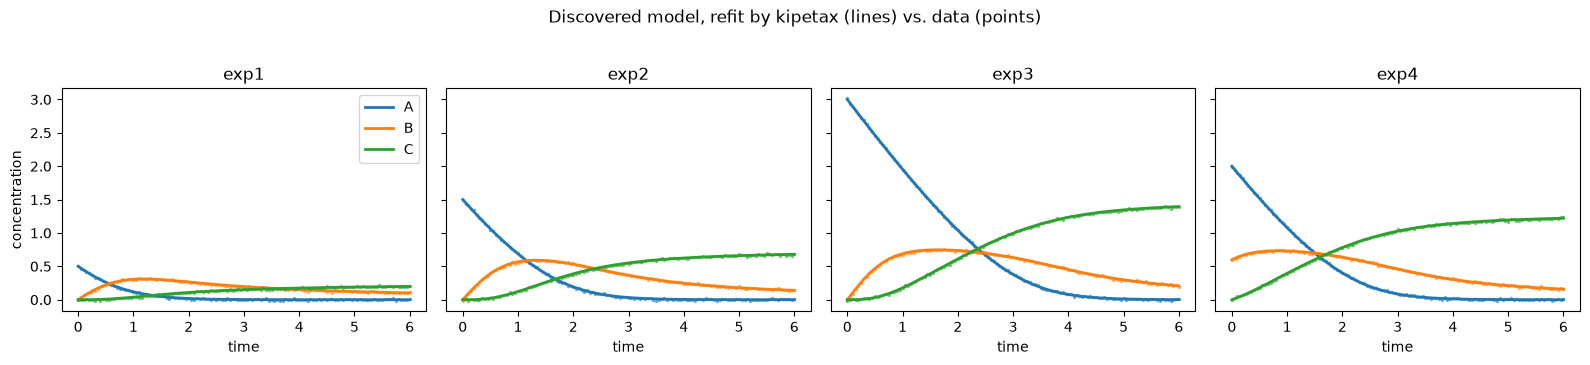

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5), sharey=True)
for ax, (name, df) in zip(axes, data.items()):
    Z = ro.experiments[name].Z
    for comp, color in zip('ABC', ['tab:blue', 'tab:orange', 'tab:green']):
        ax.plot(df.index, df[comp], '.', ms=3, color=color, alpha=0.5)
        ax.plot(Z.index, Z[comp], '-', color=color, lw=2, label=comp)
    ax.set_title(name)
    ax.set_xlabel('time')
axes[0].set_ylabel('concentration')
axes[0].legend()
fig.suptitle('Discovered model, refit by kipetax (lines) vs. data (points)', y=1.03)
plt.tight_layout()
plt.show()

## When the noise is larger

Double the noise ($\sigma = 0.02$). Rate estimates from differentiated data
degrade faster than the data themselves, so derivative-based selection becomes
less reliable. How much less? Repeat steps 1 to 3 on eight independent noise
draws and check each selection against the true forms:

In [11]:
import re

SIGMA_HI = 0.02


def true_forms(m1, m2):
    one_saturating_A = (len(m1.selected_features_) == 1 and
                        re.fullmatch(r'A/\(1\+[0-9.]+\*A\)', m1.selected_features_[0]))
    return bool(one_saturating_A) and list(m2.selected_features_) == ['B^2']


draws, rows = {}, []
for seed in range(11, 19):
    d = make_data(SIGMA_HI, seed=seed)
    Xd, r1d, r2d, _ = estimate_rates(d, window=25)
    m1, m2 = discover(library_r1(), Xd, r1d), discover(library_r2(), Xd, r2d)
    draws[seed] = (d, Xd, r1d, r2d, m1, m2)
    rows.append({'noise seed': seed, 'r1': m1.expression_[4:], 'r2': m2.expression_[4:],
                 'true forms': true_forms(m1, m2)})
pd.set_option('display.max_colwidth', 80)
stability = pd.DataFrame(rows).set_index('noise seed')
stability

,r1,r2,true forms
noise seed,,,
11,1.89*A/(1+1.364*A),0.8187*B^2/(1+0.05*B),False
12,3.851*A/(1+0.4585*A) - 2.222*A/(1+0.05*B) + 0.3195*A^2,0.843*B^2 - 0.5475*B^2/(1+18.52*B),False
13,2.904*A/(1+0.5541*A) - 1.224*A + 0.1708*A^2,0.8117*B^2 - 0.1333*B^2/(1+16.15*B),False
14,1.863*A/(1+1.343*A),0.8483*B^2/(1+0.09249*B),False
15,1.84*A/(1+1.142*A) - 0.09146*A/(1+0.9888*B),0.8389*B^2/(1+0.0727*B),False
16,1.829*A/(1+1.025*A) - 0.1098*A/(1+0.3586*C),0.8573*B^2/(1+0.1221*B),False
17,1.818*A/(1+0.9848*A) - 0.1078*A,0.85*B^2/(1+0.0604*B) - 0.02542*A*B,False
18,1.814*A/(1+1.046*A) - 0.08219*A,0.8302*B^2/(1+0.07413*B),False


None of the eight selections is exactly right, and the errors are systematic
rather than random. $r_2$ always picks up a weak saturation, $B^2/(1 + KB)$ with
a small $K$ (or an equivalent small correction to $B^2$), and $r_1$ gains a small
extra term in six of the eight draws. A consistent pattern like this is what
bias in the estimated derivatives looks like: the wider smoothing window needed
at this noise level flattens curvature, and BIC accepts small terms that absorb
the distortion, because it treats the rate estimates as if they were exact data.

jaxsr's own ranking cannot settle whether such a term is real, since its BIC was
computed from the derivatives that misled it. The trajectories can. Take the
first draw, where $r_2$ came back as $cB^2/(1 + KB)$ with a small $K$. Setting
$K = 0$ gives the simpler nested model $cB^2$. Refit both against the raw data
and compare BIC computed from the trajectory fit,
$\mathrm{BIC} = \chi^2 + p \ln n$. This is a small preview of choosing terms by
trajectory fit rather than by derivative fit.

In [12]:
bad = [seed for seed, row in stability.iterrows() if not row['true forms']]
print(f'selections with spurious or wrong terms: {len(bad)} of {len(stability)}')
seed = bad[0]
d, Xd, r1d, r2d, m1, m2 = draws[seed]

expr_r1, expr_r2 = as_sympy(m1), as_sympy(m2)
K_r2 = sp.fraction(sp.together(expr_r2))[1].atoms(sp.Float)   # constants in r2's denominator
nested_r2 = expr_r2.subs({K: 0 for K in K_r2})

candidates = {}
for label, (e1, e2) in [('jaxsr selection', (expr_r1, expr_r2)),
                        ('with K = 0 in r2', (expr_r1, nested_r2))]:
    t1, s1 = parametrize(e1, 'r1')
    t2, s2 = parametrize(e2, 'r2')
    fit = refit({'r1': t1, 'r2': t2}, {**s1, **s2}, d, SIGMA_HI, label.replace(' ', '_').replace('=', ''))
    candidates[label] = (t1, t2, {**s1, **s2}, fit)

print(f'\nnoise seed {seed}')
for label, (t1, t2, seeds, fit) in candidates.items():
    print(f'{label:18s} r1 = {t1}   r2 = {t2}')
    print(f'{"":18s} chi^2 = {fit.objective:.1f}, parameters = {len(seeds)}, BIC = {fit.bic:.1f}')
    print(f'{"":18s} refit: ' + ', '.join(f'{k} = {float(v):.4f}' for k, v in sorted(fit.P.items())))

selections with spurious or wrong terms: 8 of 8



noise seed 11
jaxsr selection    r1 = A*r1_2/(A*r1_1 + 1)   r2 = B**2*r2_2/(B*r2_1 + 1)
                   chi^2 = 370.9, parameters = 4, BIC = 394.5
                   refit: r1_1 = 1.5485, r1_2 = 2.0591, r2_1 = 0.0413, r2_2 = 0.8150
with K = 0 in r2   r1 = A*r1_2/(A*r1_1 + 1)   r2 = B**2*r2_1
                   chi^2 = 371.4, parameters = 3, BIC = 389.1
                   refit: r1_1 = 1.5593, r1_2 = 2.0691, r2_1 = 0.7959


In [13]:
t1, t2, seeds, fit = candidates['with K = 0 in r2']
compare(rate_constant_names(t1, t2), seeds, fit.P)

,true,jaxsr (derivatives),kipetax refit (trajectories),jaxsr error %,refit error %
k1,2.0,1.890,2.069,-5.478,3.457
K,1.5,1.364,1.559,-9.067,3.952
k2,0.8,0.819,0.796,2.335,-0.514


Dropping $K$ raises $\chi^2$ by only 0.5, far less than the $\ln n \approx 5.9$
that BIC charges for a parameter, so the trajectory fit prefers the simpler
$cB^2$ by 5.4 BIC units. When $K$ is kept, the refit shrinks it only from 0.05 to
0.04 rather than to zero: the data cannot pin it down, which is exactly why it
should go.

Refitting the nested model also moves every constant toward the truth: $K$ from
9% low to 4% high, $k_1$ from 5.5% low to 3.5% high, and $k_2$ from 2.3% high to
0.5% low.

## Summary and caveats

- **Library design matters more than the algorithm.** Requiring each rate to
  vanish without its reactant, and offering competing mechanisms, is what lets a
  sparse regression find a chemically meaningful law.
- **Experiments must exercise the rate law.** Saturation is only identifiable
  because the initial charges span a wide range of $A$; a single experiment
  would leave it confused with a polynomial.
- **Derivative-based discovery degrades with noise.** It proposes candidates;
  the kipetax refit on raw trajectories, with trajectory-based BIC, is the check.
- **Stoichiometry is assumed known** here. If it is not, the consistency check
  in step 1 is where that shows up.
- **No confidence intervals yet** for this refit: `ReactionSet` does not compute
  a covariance. For a single experiment, `ReactionModel.run_opt(covariance=True)`
  does.